In [11]:
%pip install -q planetary-computer pystac-client odc-stac rioxarray matplotlib

Note: you may need to restart the kernel to use updated packages.


In [15]:
import requests, datetime as dt
from pystac_client import Client

# 1. Fresh token straight from the API, with a clock check
r = requests.get("https://planetarycomputer.microsoft.com/api/sas/v1/token/landsat-c2-l2").json()
print("Your PC time (UTC):", dt.datetime.now(dt.timezone.utc))
print("Token expires     :", r["msft:expiry"])
token = r["token"]

Your PC time (UTC): 2026-09-30 20:03:50.597928+00:00
Token expires     : 2026-09-30T20:48:50Z


In [16]:
from odc.stac import load, configure_rio
import matplotlib.pyplot as plt
import rioxarray

configure_rio(cloud_defaults=True)
bbox = [73.65, 18.30, 74.10, 18.75]

catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")  # no modifier
items = list(catalog.search(
    collections=["landsat-c2-l2"], bbox=bbox,
    datetime="2023-02-01/2023-05-31",          # start small to test
    query={"eo:cloud_cover": {"lt": 10},
           "platform": {"in": ["landsat-8", "landsat-9"]}}).items())
print("Scenes found:", len(items))

for item in items:
    for asset in item.assets.values():
        if "landsateuwest.blob.core.windows.net" in asset.href and "?" not in asset.href:
            asset.href = asset.href + "?" + token

# Quick reachability test (expect 200 or 206)
print("HTTP status:", requests.get(items[0].assets["qa_pixel"].href,
                                   headers={"Range": "bytes=0-100"}).status_code)

Scenes found: 8
HTTP status: 206


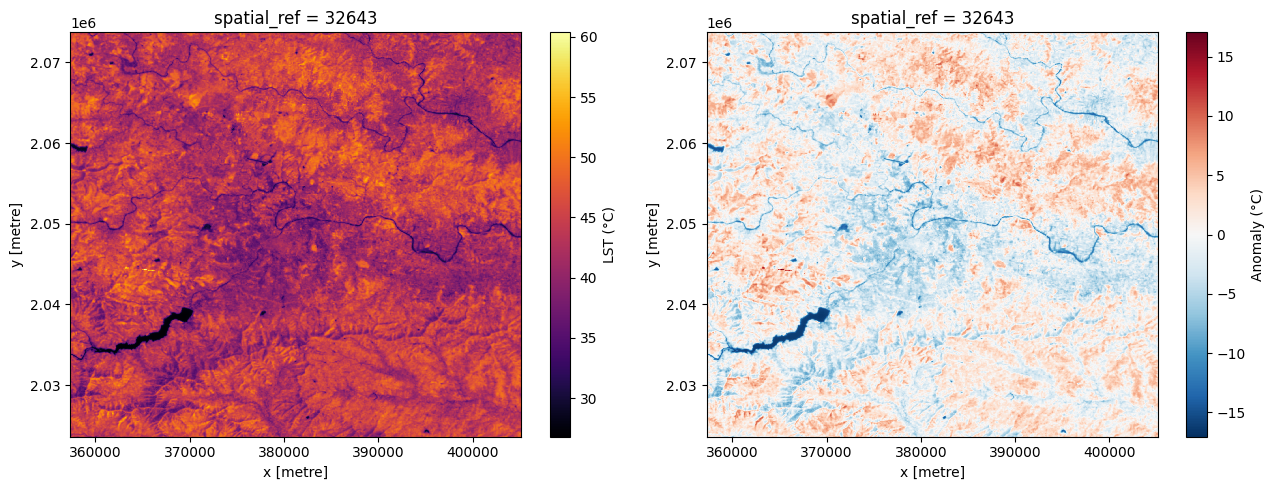

In [17]:
ds = load(items, bands=["lwir11", "qa_pixel", "red", "nir08"],
          bbox=bbox, crs="EPSG:32643", resolution=30,
          groupby="solar_day", chunks={}, fail_on_error=False).compute()

bad = (ds["qa_pixel"].astype("uint16") & 0b11111) != 0
lst = (ds["lwir11"].where(ds["lwir11"] > 0) * 0.00341802 + 149.0 - 273.15).where(~bad)
lst_mean = lst.mean("time")
lst_anom = lst_mean - lst_mean.mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lst_mean.plot(ax=ax[0], cmap="inferno", cbar_kwargs={"label": "LST (°C)"})
lst_anom.plot(ax=ax[1], cmap="RdBu_r", center=0, cbar_kwargs={"label": "Anomaly (°C)"})
plt.tight_layout(); plt.savefig("pune_lst.png", dpi=150); plt.show()
lst_mean.rio.to_raster("pune_lst_mean.tif")

Urban mean LST: 42.6 °C | Non-urban: 44.4 °C | Urban minus non-urban: -1.9 °C


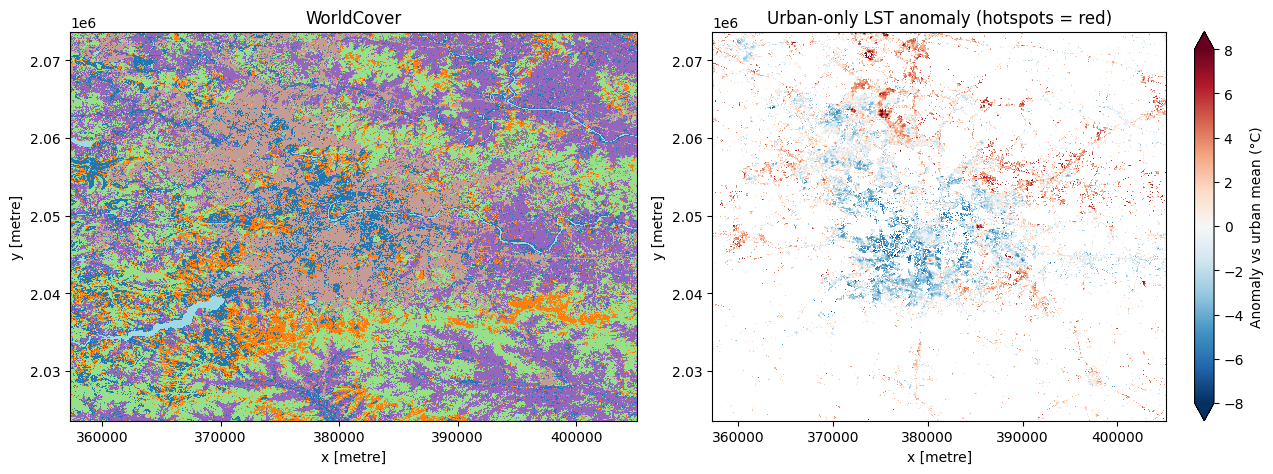

In [18]:
# Continue in the same notebook (ds, lst_mean, catalog, bbox already exist)
wc_items = [pc.sign(i) for i in catalog.search(
    collections=["esa-worldcover"], bbox=bbox, datetime="2021").items()]
wc = load(wc_items, bands=["map"], like=ds, resampling="mode", chunks={}).compute()
lc = wc["map"].isel(time=0)

urban = (lc == 50)                        # built-up
nonurban = lc.isin([30, 40, 60])          # grass, cropland, bare

u = lst_mean.where(urban).mean().item()
n = lst_mean.where(nonurban).mean().item()
print(f"Urban mean LST: {u:.1f} °C | Non-urban: {n:.1f} °C | Urban minus non-urban: {u-n:+.1f} °C")

# Anomaly inside the city only
urban_anom = (lst_mean - u).where(urban)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lc.plot(ax=ax[0], cmap="tab20", add_colorbar=False); ax[0].set_title("WorldCover")
urban_anom.plot(ax=ax[1], cmap="RdBu_r", center=0,
                vmin=-8, vmax=8, cbar_kwargs={"label": "Anomaly vs urban mean (°C)"})
ax[1].set_title("Urban-only LST anomaly (hotspots = red)")
plt.tight_layout(); plt.savefig("pune_urban_hotspots.png", dpi=150); plt.show()

In [1]:
%pip install -q osmnx geopandas

Note: you may need to restart the kernel to use updated packages.


Buildings: 63643
Buildings with a height or levels tag: 1.4%


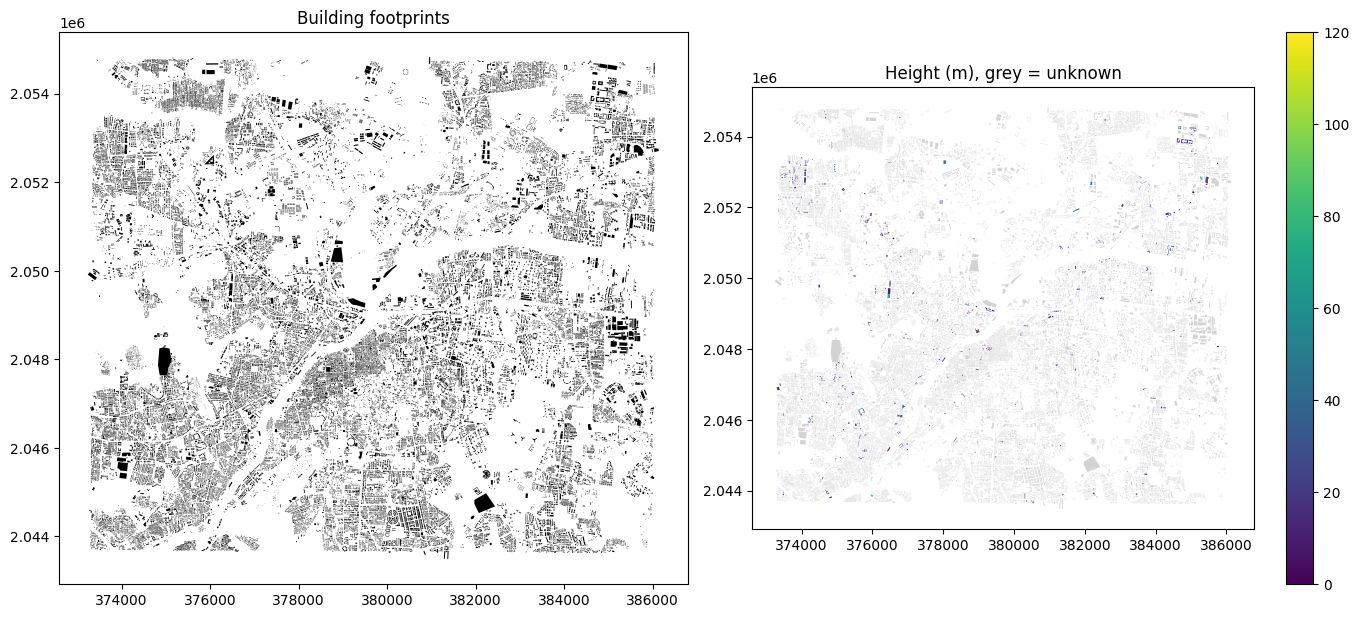

In [2]:
import re, numpy as np, geopandas as gpd, osmnx as ox
import matplotlib.pyplot as plt

# osmnx >= 2.0 order: (west, south, east, north). On osmnx 1.x use (north, south, east, west).
bbox = (73.80, 18.48, 73.92, 18.58)

b = ox.features_from_bbox(bbox, tags={"building": True})
b = b[b.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
b = b.to_crs(32643)                       # metres
b["area_m2"] = b.geometry.area
print("Buildings:", len(b))

def num(x):
    if x is None or (isinstance(x, float) and np.isnan(x)): return np.nan
    m = re.search(r"[\d.]+", str(x))
    return float(m.group()) if m else np.nan

h = b["height"].map(num) if "height" in b else np.nan
lv = b["building:levels"].map(num) if "building:levels" in b else np.nan
b["height_m"] = np.where(~np.isnan(h), h, lv * 3.0)      # 3 m per storey assumption
print(f"Buildings with a height or levels tag: {b['height_m'].notna().mean():.1%}")

cols = ["geometry", "building", "area_m2", "height_m"]
b[cols].to_file("pune_buildings.gpkg", driver="GPKG")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
b.plot(ax=ax[0], color="k", linewidth=0); ax[0].set_title("Building footprints")
b.plot(ax=ax[1], column="height_m", cmap="viridis", legend=True,
       missing_kwds={"color": "lightgrey"}, linewidth=0)
ax[1].set_title("Height (m), grey = unknown")
plt.tight_layout(); plt.savefig("pune_buildings.png", dpi=150); plt.show()

In [3]:
%pip install -q plotly pydeck

Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np, requests
import plotly.graph_objects as go
from pystac_client import Client
from odc.stac import load, configure_rio

configure_rio(cloud_defaults=True)

BBOX_STUDY = [73.65, 18.30, 74.10, 18.75]          # W, S, E, N (Landsat/DEM box)
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

def sign_fresh(items, collection):
    tok = requests.get(
        f"https://planetarycomputer.microsoft.com/api/sas/v1/token/{collection}").json()["token"]
    for it in items:
        for a in it.assets.values():
            if "blob.core.windows.net" in a.href and "?" not in a.href:
                a.href += "?" + tok
    return items

items = list(catalog.search(
    collections=["landsat-c2-l2"], bbox=BBOX_STUDY,
    datetime="2023-02-01/2023-05-31",
    query={"eo:cloud_cover": {"lt": 10},
           "platform": {"in": ["landsat-8", "landsat-9"]}}).items())
print("Scenes found:", len(items))
items = sign_fresh(items, "landsat-c2-l2")

ds = load(items, bands=["lwir11", "qa_pixel"], bbox=BBOX_STUDY,
          crs="EPSG:32643", resolution=30, groupby="solar_day",
          chunks={}, fail_on_error=False).compute()

bad = (ds["qa_pixel"].astype("uint16") & 0b11111) != 0
lst = (ds["lwir11"].where(ds["lwir11"] > 0) * 0.00341802 + 149.0 - 273.15).where(~bad)
lst_mean = lst.mean("time")
print("LST ready:", lst_mean.shape)

Scenes found: 8
LST ready: (1671, 1595)


In [8]:
import rioxarray as rxr
from rioxarray.merge import merge_arrays
from rasterio.enums import Resampling

def dem_tile(lat, lon):
    name = f"Copernicus_DSM_COG_10_N{lat:02d}_00_E{lon:03d}_00_DEM"
    return f"https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif"

W, S, E, N = BBOX_STUDY
tiles = []
for lon in (73, 74):
    t_ = rxr.open_rasterio(dem_tile(18, lon), chunks=True).squeeze(drop=True)
    tiles.append(t_.rio.clip_box(W, S, E, N))       # read only the Pune window

mosaic = merge_arrays(tiles)

lst_mean = lst_mean.rio.write_crs("EPSG:32643")     # make sure the CRS is attached
elev = mosaic.rio.reproject_match(lst_mean, resampling=Resampling.bilinear).compute()
print("DEM ready:", elev.shape, "| range (m):", float(elev.min()), "to", float(elev.max()))

DEM ready: (1671, 1595) | range (m): 517.0 to 1314.3642578125


In [16]:
import numpy as np, xarray as xr, rioxarray, time
from odc.stac import load

RES = 30          # change to 60 if you run out of memory
t0 = time.time()

# --- Landsat 2022-2025, dry season, LST + indices ---
items = list(catalog.search(
    collections=["landsat-c2-l2"], bbox=BBOX_STUDY,
    datetime="2022-02-01/2025-05-31",
    query={"eo:cloud_cover": {"lt": 10},
           "platform": {"in": ["landsat-8", "landsat-9"]}}).items())
items = [i for i in items if i.datetime.month in (2, 3, 4, 5)]
print("Scenes:", len(items))
items = sign_fresh(items, "landsat-c2-l2")

raw = load(items, bands=["lwir11", "qa_pixel", "blue", "green", "red",
                         "nir08", "swir16", "swir22"],
           bbox=BBOX_STUDY, crs="EPSG:32643", resolution=RES,
           groupby="solar_day", chunks={"x": 512, "y": 512},
           fail_on_error=False)

bad = (raw["qa_pixel"].astype("uint16") & 0b11111) != 0
sr = lambda b: (raw[b].where(raw[b] > 0) * 0.0000275 - 0.2).where(~bad)
blue, green, red, nir, sw1, sw2 = (sr(b) for b in
    ["blue", "green", "red", "nir08", "swir16", "swir22"])

lst    = (raw["lwir11"].where(raw["lwir11"] > 0) * 0.00341802 + 149.0 - 273.15).where(~bad)
ndvi   = (nir - red) / (nir + red)
ndbi   = (sw1 - nir) / (sw1 + nir)
mndwi  = (green - sw1) / (green + sw1)
albedo = 0.356*blue + 0.130*red + 0.373*nir + 0.085*sw1 + 0.072*sw2 - 0.0018

stack = xr.Dataset({
    "LST": lst.mean("time"), "NDVI": ndvi.mean("time"),
    "NDBI": ndbi.mean("time"), "MNDWI": mndwi.mean("time"),
    "ALBEDO": albedo.mean("time"),
    "LST_std": lst.std("time"),
    "n_obs": lst.notnull().sum("time"),
}).compute()
print(f"Landsat stack done in {time.time()-t0:.0f} s")

# save immediately, so the slow part is never repeated
stack.drop_vars("spatial_ref", errors="ignore").to_netcdf("pune_landsat_stack.nc")

# --- DEM (from your AWS step) ---
stack["ELEV"] = elev.reindex_like(stack["LST"], method="nearest")

Scenes: 39
Landsat stack done in 566 s


In [17]:
# --- ESA WorldCover ---
wc_items = sign_fresh(list(catalog.search(collections=["esa-worldcover"],
                       bbox=BBOX_STUDY, datetime="2021-01-01/2021-12-31").items()),
                      "esa-worldcover")
wc = load(wc_items, bands=["map"], bbox=BBOX_STUDY, crs="EPSG:32643",
          resolution=RES, resampling="mode", chunks={}).compute()
stack["LANDCOVER"] = wc["map"].isel(time=0)

stack = stack.where(stack["n_obs"] >= 5)
stack.drop_vars("spatial_ref", errors="ignore").to_netcdf("pune_features.nc")
print("Saved. Urban pixels (WorldCover 50):", int((stack["LANDCOVER"] == 50).sum()))

Saved. Urban pixels (WorldCover 50): 471450


In [18]:
import numpy as np, plotly.graph_objects as go
from scipy.ndimage import gaussian_filter

f = 5   # 30 m -> 150 m; use 8 or 10 if the browser is slow

z = elev.sortby("y").coarsen(y=f, x=f, boundary="trim").mean()
t = lst_mean.sortby("y").coarsen(y=f, x=f, boundary="trim").mean()

X = (z.x.values - z.x.values.min()) / 1000      # km east
Y = (z.y.values - z.y.values.min()) / 1000      # km north
Z = z.values
T = t.values

# ---------- View 1: terrain coloured by temperature ----------
fig1 = go.Figure(go.Surface(
    x=X, y=Y, z=Z, surfacecolor=T, colorscale="Inferno",
    cmin=np.nanpercentile(T, 2), cmax=np.nanpercentile(T, 98),
    colorbar=dict(title="LST (°C)")))
fig1.update_layout(
    title="Pune: terrain coloured by Landsat LST",
    scene=dict(xaxis_title="East (km)", yaxis_title="North (km)",
               zaxis_title="Elevation (m)",
               aspectmode="manual", aspectratio=dict(x=1, y=1, z=0.25)),
    height=750)
fig1.write_html("pune_3d_terrain_lst.html")
fig1.show()

# ---------- View 2: LST anomaly as the height (peaks = hotspots) ----------
A = np.where(np.isnan(T), np.nanmean(T), T)
anom = gaussian_filter(A - np.nanmean(A), sigma=1.5)

fig2 = go.Figure(go.Surface(
    x=X, y=Y, z=anom, colorscale="RdBu_r", cmid=0,
    colorbar=dict(title="Anomaly (°C)"),
    contours=dict(z=dict(show=True, usecolormap=True, project_z=True))))
fig2.update_layout(
    title="Pune: LST anomaly surface (peaks = hotspots)",
    scene=dict(xaxis_title="East (km)", yaxis_title="North (km)",
               zaxis_title="Anomaly (°C)",
               aspectmode="manual", aspectratio=dict(x=1, y=1, z=0.4)),
    height=750)
fig2.write_html("pune_3d_hotspot_surface.html")
fig2.show()